In [7]:
import keras
from keras.datasets import california_housing

(train_data, train_targets), (test_data, test_targets) = (
    california_housing.load_data(version="small")
)


In [8]:
mean = train_data.mean(axis=0)
std = train_data.std(axis=0)
x_train = (train_data - mean) / std
x_test = (test_data - mean) / std

In [9]:
y_train = train_targets / 100_000
y_test = test_targets / 100_000

In [10]:
def get_model() -> keras.models.Sequential:
    model = keras.models.Sequential([
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(1),
    ])
    model.compile(
        optimizer = "adam",
        loss="mean_squared_error",
        metrics=["mean_absolute_error"]
    )
    return model

In [12]:
import numpy as np

k = 4
num_val_samples = len(x_train) // k
num_epochs = 50
all_scores = []

for i in range(k):
    print(f"Fold {i+1}")
    fold_x_val = x_train[i * num_val_samples : (i+1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i+1) * num_val_samples]

    fold_x_train = np.concat([x_train[:i * num_val_samples], x_train[(i+1) * num_val_samples :]], axis=0)
    fold_y_train = np.concat([y_train[:i * num_val_samples], y_train[(i+1) * num_val_samples :]], axis=0)

    model = get_model()
    model.fit(
        fold_x_train,
        fold_y_train,
        epochs=num_epochs,
        batch_size=16,
        verbose=0
    )
    score = model.evaluate(fold_x_val, fold_y_val, verbose=0)
    val_loss, val_mae = score
    all_scores.append(val_mae)

Fold 1
Fold 2
Fold 3
Fold 4


In [15]:
np.mean(all_scores)

np.float64(0.27535682916641235)

In [17]:
k = 4
num_val_samples = len(x_train) // k
num_epochs = 200
all_mae_histories = []
for i in range(k):
    print(f"Processing fold #{i + 1}")
    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    model = get_model()
    history = model.fit(
        fold_x_train,
        fold_y_train,
        validation_data=(fold_x_val, fold_y_val),
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )
    mae_history = history.history["val_mean_absolute_error"]
    all_mae_histories.append(mae_history)

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


In [18]:
average_mae_history = [
    np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)
]

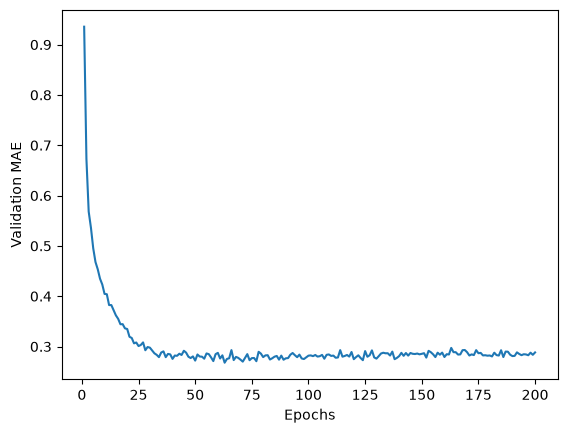

In [19]:
import matplotlib.pyplot as plt

epochs = range(1, len(average_mae_history) + 1)
plt.plot(epochs, average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [25]:
predictions = model.predict(x_test)
print(f"Predicted average price: ${predictions[0][0]*100000:.0f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Predicted average price: $214338
